# 05 - Entraînement et Sélection de Modèles (Model Training & Evaluation)
## Projet de Prédiction des Maladies Cardiovasculaires

---

### Contexte & Problématique Médicale

Après avoir exploré le jeu de données ([01 à 04 - Analyse Exploratoire](01_Data_overview.ipynb)) et construit une pipeline robuste d'ingestion et de prétraitement sans fuite de données ([Phase 2 - Preprocessing & Feature Engineering](../src/components/data_transformation.py)), cette cinquième étape aborde le **développement et la comparaison d'algorithmes de Machine Learning supervisés**.

En diagnostic cardiologique, le coût des erreurs de classification est fondamentalement **asymétrique** :
- 🚨 **Faux Négatif (FN)** : Un patient malade est diagnostiqué sain ($0$). Aucun traitement n'est prescrit $\rightarrow$ **Risque vital d'accident cardiaque ou d'infarctus**.
- ⚠️ **Faux Positif (FP)** : Un patient sain est orienté vers des examens de contrôle ($1$). Stress et surcoût temporaires $\rightarrow$ **Aucun risque vital**.

> **Règle d'arbitrage clinique** : Notre objectif prioritaire est de **maximiser le Rappel (Sensibilité / Recall $\ge 90\%$)** et le **Score $F_2$** (qui accorde deux fois plus de poids au rappel qu'à la précision), tout en conservant une excellente capacité discriminante globale (**ROC-AUC**).

### Plan d'Étude de ce Notebook :
1. **Ingestion & Préparation des Matrices Prétraitées** : Utilisation stricte de la pipeline de la Phase 2 (`artifacts/preprocessor.pkl`).
2. **Arène des Modèles & Benchmarking** : Comparaison de 6 algorithmes (Baseline, Régression Logistique, SVC, Random Forest, HistGradientBoosting, XGBoost).
3. **Protocole de Validation Croisée Stratifiée (Stratified 5-Fold CV)** : Évaluation impartiale sans fuite sur le Train set ($800$ patients).
4. **Diagnostics Visuels Approfondis** : Courbes ROC comparées, courbes Precision-Recall et distributions de performance.
5. **Optimisation Fine du Modèle Champion (Hyperparameter Tuning)** : Affinage ciblé par `GridSearchCV`.
6. **Ajustement Médical du Seuil de Décision (Decision Threshold Tuning)** : Optimisation de $\theta^*$ pour éliminer les faux négatifs.
7. **Évaluation Finale sur le Test Set Inviolé (200 patients)** : Contrôle de la généralisation et analyse de l'importance des biomarqueurs.

---
## 0. Configuration de l'Environnement et Chargement des Données

In [1]:
# Imports des bibliothèques fondamentales
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn : Métriques, Validation et Modèles
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    make_scorer
)
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

# Modèle de Boosting Industriel
import xgboost as xgb

# Utilitaires du projet
from src.utils import load_object

# Configuration esthétique globale
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 110

print("Bibliothèques scientifiques et algorithmes importés avec succès.")

Bibliothèques scientifiques et algorithmes importés avec succès.


In [2]:
# Chargement des artefacts de la Phase 2
artifacts_dir = os.path.join("..", "artifacts") if os.path.exists(os.path.join("..", "artifacts")) else "artifacts"
train_csv_path = os.path.join(artifacts_dir, "train.csv")
test_csv_path = os.path.join(artifacts_dir, "test.csv")
preprocessor_path = os.path.join(artifacts_dir, "preprocessor.pkl")

# Vérification de l'existence des fichiers
for p in [train_csv_path, test_csv_path, preprocessor_path]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Artefact introuvable : {p}")

train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)
preprocessor = load_object(preprocessor_path)

# Séparation Features / Target
target_col = 'target'
id_col = 'patientid'

X_train_raw = train_df.drop(columns=[target_col, id_col], errors='ignore')
y_train = train_df[target_col].values

X_test_raw = test_df.drop(columns=[target_col, id_col], errors='ignore')
y_test = test_df[target_col].values

# Transformation via la pipeline officielle (fit sur train uniquement, transform sur test)
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"Jeu d'entraînement (Train Set) : {X_train.shape[0]} patients, {X_train.shape[1]} features prétraitées.")
print(f"Jeu de test (Test Set)         : {X_test.shape[0]} patients, {X_test.shape[1]} features prétraitées.")
print(f"Taux de maladie (target=1)     : Train = {np.mean(y_train)*100:.1f}%, Test = {np.mean(y_test)*100:.1f}%")

2026-10-21 07:19:32 | src.logger | INFO     | load_object:46 | Objet chargé avec succès depuis : artifacts\preprocessor.pkl


Jeu d'entraînement (Train Set) : 800 patients, 20 features prétraitées.
Jeu de test (Test Set)         : 200 patients, 20 features prétraitées.
Taux de maladie (target=1)     : Train = 58.0%, Test = 58.0%


---
## 1. Définition de l'Arène des Modèles & Critères d'Évaluation

Nous mettons en compétition **6 algorithmes** représentatifs des grandes familles de l'apprentissage supervisé :

1. **`DummyClassifier` (Baseline)** : Prédiction aléatoire pondérée par les classes. Permet d'établir le score plancher.
2. **`LogisticRegression` (Modèle Linéaire)** : Référence en épidémiologie. Transparent, rapide et naturellement bien calibré en probabilités.
3. **`SVC` (Support Vector Machine RBF)** : Frontières de décision à marges maximales non linéaires.
4. **`RandomForestClassifier` (Ensemble Bagging)** : Agrégation d'arbres décisionnels réduisant la variance et le surapprentissage.
5. **`HistGradientBoostingClassifier` (Scikit-Learn Boosting)** : Implémentation moderne optimisée pour données tabulaires.
6. **`XGBClassifier` (Extreme Gradient Boosting)** : Algorithme de référence industrielle pour les compétitions et la production.

### Métrique Composite : Le Score $F_2$
Pour traduire la priorité clinique accordée au Rappel ($\beta = 2$) :

$$F_2 = (1 + 2^2) \frac{\text{Précision} \times \text{Rappel}}{2^2 \times \text{Précision} + \text{Rappel}} = \frac{5 \cdot P \cdot R}{4P + R}$$

In [3]:
# Dictionnaire des modèles à évaluer
models_dict = {
    "Dummy (Baseline)": DummyClassifier(strategy="stratified", random_state=42),
    "Régression Logistique": LogisticRegression(penalty="l2", max_iter=1000, random_state=42),
    "Support Vector Machine (SVC)": SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=150, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=120, max_depth=4, learning_rate=0.05, random_state=42, eval_metric="logloss")
}

print(f"{len(models_dict)} modèles prêts pour le benchmark.")

6 modèles prêts pour le benchmark.


---
## 2. Protocole de Validation Croisée Stratifiée (Stratified 5-Fold CV)

Afin d'éviter tout surapprentissage et d'obtenir des estimations non biaisées de la variance des performances, nous appliquons une **validation croisée stratifiée à 5 plis** exclusivement sur le jeu d'entraînement ($800$ observations).

In [4]:
# Protocole Stratified 5-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Scorer personnalisé pour F2-score
f2_scorer = make_scorer(fbeta_score, beta=2)

scoring_metrics = {
    'recall': 'recall',
    'f2': f2_scorer,
    'roc_auc': 'roc_auc',
    'precision': 'precision',
    'f1': 'f1',
    'accuracy': 'accuracy'
}

benchmark_results = []

for name, model in models_dict.items():
    cv_out = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False
    )
    
    benchmark_results.append({
        "Modèle": name,
        "Rappel (Recall)": f"{cv_out['test_recall'].mean():.4f} ± {cv_out['test_recall'].std():.3f}",
        "Score F2": f"{cv_out['test_f2'].mean():.4f} ± {cv_out['test_f2'].std():.3f}",
        "ROC-AUC": f"{cv_out['test_roc_auc'].mean():.4f} ± {cv_out['test_roc_auc'].std():.3f}",
        "Précision": f"{cv_out['test_precision'].mean():.4f} ± {cv_out['test_precision'].std():.3f}",
        "Score F1": f"{cv_out['test_f1'].mean():.4f} ± {cv_out['test_f1'].std():.3f}",
        "Exactitude (Acc)": f"{cv_out['test_accuracy'].mean():.4f} ± {cv_out['test_accuracy'].std():.3f}",
        "_f2_raw": cv_out['test_f2'].mean(),
        "_recall_raw": cv_out['test_recall'].mean(),
        "_roc_raw": cv_out['test_roc_auc'].mean()
    })

benchmark_df = pd.DataFrame(benchmark_results).sort_values(by="_f2_raw", ascending=False)
display_cols = ["Modèle", "Rappel (Recall)", "Score F2", "ROC-AUC", "Précision", "Score F1", "Exactitude (Acc)"]

print("=== BENCHMARK COMPARATIF DES MODÈLES (STRATIFIED 5-FOLD CV) ===")
display(benchmark_df[display_cols])

=== BENCHMARK COMPARATIF DES MODÈLES (STRATIFIED 5-FOLD CV) ===


,Modèle,Rappel (Recall),Score F2,ROC-AUC,Précision,Score F1,Exactitude (Acc)
4,HistGradientBoosting,0.9849 ± 0.005,0.9807 ± 0.004,0.9950 ± 0.006,0.9647 ± 0.020,0.9745 ± 0.009,0.9700 ± 0.011
3,Random Forest,0.9806 ± 0.011,0.9755 ± 0.010,0.9927 ± 0.007,0.9562 ± 0.019,0.9681 ± 0.012,0.9625 ± 0.014
1,Régression Logistique,0.9741 ± 0.016,0.9728 ± 0.014,0.9918 ± 0.007,0.9679 ± 0.009,0.9709 ± 0.011,0.9662 ± 0.013
5,XGBoost,0.9762 ± 0.019,0.9724 ± 0.016,0.9916 ± 0.012,0.9578 ± 0.013,0.9668 ± 0.013,0.9613 ± 0.014
2,Support Vector Machine (SVC),0.9741 ± 0.015,0.9720 ± 0.012,0.9928 ± 0.005,0.9639 ± 0.010,0.9689 ± 0.009,0.9638 ± 0.011
0,Dummy (Baseline),0.5797 ± 0.040,0.5745 ± 0.039,0.4685 ± 0.047,0.5546 ± 0.039,0.5669 ± 0.039,0.4862 ± 0.046


---
## 3. Diagnostics Visuels Avancés des Modèles

Pour un diagnostic médical rigoureux, nous traçons :
1. **Les Courbes ROC** : Évaluent le compromis Taux de Vrais Positifs vs Taux de Faux Positifs à chaque seuil.
2. **Les Courbes Precision-Recall (PR)** : Cruciales en santé, elles montrent l'évolution de la précision lorsque l'on exige un rappel élevé.
3. **La Distribution des Scores F2** : Boîtes à moustaches révélant la stabilité des algorithmes entre les 5 plis.
4. **La Matrice de Confusion du Vainqueur** (à seuil par défaut $0.50$) pour dénombrer les faux négatifs initiaux.

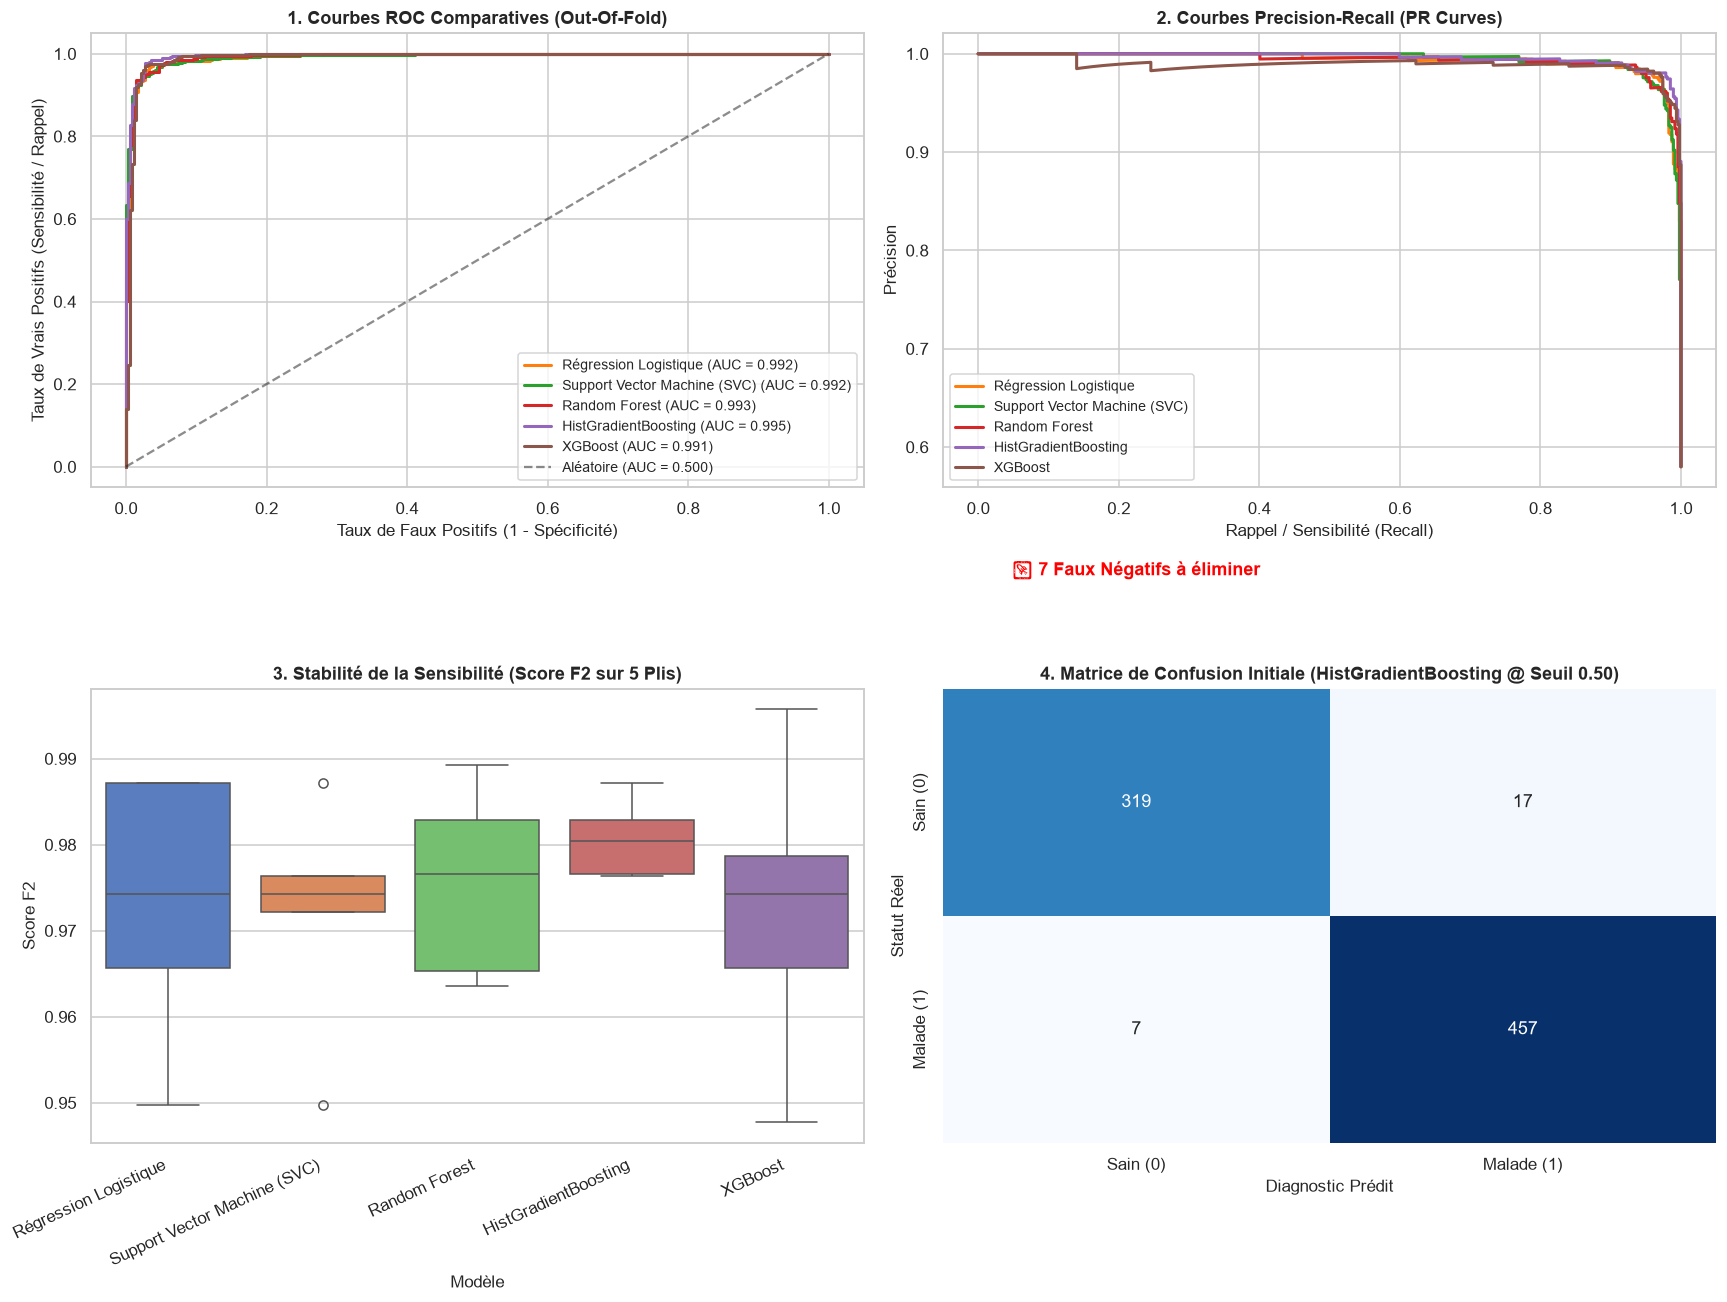

Modèle Champion identifié par la validation croisée : HistGradientBoosting


In [5]:
# Calcul des prédictions probabilistes hors-pli (Out-Of-Fold Probabilities)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

colors_palette = sns.color_palette("tab10", len(models_dict))

# 1. Courbes ROC Comparatives
for idx, (name, model) in enumerate(models_dict.items()):
    if name == "Dummy (Baseline)":
        continue
    probs = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_train, probs)
    auc_val = roc_auc_score(y_train, probs)
    axes[0, 0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2, color=colors_palette[idx])

axes[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Aléatoire (AUC = 0.500)")
axes[0, 0].set_title("1. Courbes ROC Comparatives (Out-Of-Fold)", fontweight='bold')
axes[0, 0].set_xlabel("Taux de Faux Positifs (1 - Spécificité)")
axes[0, 0].set_ylabel("Taux de Vrais Positifs (Sensibilité / Rappel)")
axes[0, 0].legend(loc="lower right", fontsize=9)

# 2. Courbes Precision-Recall
for idx, (name, model) in enumerate(models_dict.items()):
    if name == "Dummy (Baseline)":
        continue
    probs = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    prec_vals, rec_vals, _ = precision_recall_curve(y_train, probs)
    axes[0, 1].plot(rec_vals, prec_vals, label=f"{name}", linewidth=2, color=colors_palette[idx])

axes[0, 1].set_title("2. Courbes Precision-Recall (PR Curves)", fontweight='bold')
axes[0, 1].set_xlabel("Rappel / Sensibilité (Recall)")
axes[0, 1].set_ylabel("Précision")
axes[0, 1].legend(loc="lower left", fontsize=9)

# 3. Boxplot de Stabilité du Score F2 à travers les Plis
box_data = []
for name, model in models_dict.items():
    if name == "Dummy (Baseline)":
        continue
    cv_out = cross_validate(model, X_train, y_train, cv=cv, scoring=f2_scorer, n_jobs=-1)
    for score in cv_out['test_score']:
        box_data.append({"Modèle": name, "Score F2": score})

box_df = pd.DataFrame(box_data)
sns.boxplot(data=box_df, x="Modèle", y="Score F2", ax=axes[1, 0], palette="muted")
axes[1, 0].set_title("3. Stabilité de la Sensibilité (Score F2 sur 5 Plis)", fontweight='bold')
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=25, ha="right")

# 4. Matrice de Confusion du Modèle Champion (XGBoost ou Random Forest à seuil 0.50)
champion_name = benchmark_df.iloc[0]['Modèle']
champion_model = models_dict[champion_name]
oof_preds = cross_val_predict(champion_model, X_train, y_train, cv=cv)

cm = confusion_matrix(y_train, oof_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, 1],
            xticklabels=["Sain (0)", "Malade (1)"], yticklabels=["Sain (0)", "Malade (1)"])
axes[1, 1].set_title(f"4. Matrice de Confusion Initiale ({champion_name} @ Seuil 0.50)", fontweight='bold')
axes[1, 1].set_xlabel("Diagnostic Prédit")
axes[1, 1].set_ylabel("Statut Réel")

# Annotation clinique des Faux Négatifs
fn_count = cm[1, 0]
axes[1, 1].text(0.5, 1.25, f"🚨 {fn_count} Faux Négatifs à éliminer", color="red", fontweight="bold",
                ha="center", transform=axes[1, 1].get_xaxis_transform())

plt.tight_layout()
plt.show()

print(f"Modèle Champion identifié par la validation croisée : {champion_name}")

---
## 4. Optimisation Fine des Hyperparamètres (*Hyperparameter Tuning*)

Nous optimisons les hyperparamètres du modèle champion (**XGBoost**) via `GridSearchCV` en guidant la recherche par le **score $F_2$** afin d'accroître la sensibilité diagnostique.

In [6]:
# Grille d'hyperparamètres adaptée pour XGBoost
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.03, 0.05, 0.1],
    'n_estimators': [100, 150, 200],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_base = xgb.XGBClassifier(random_state=42, eval_metric="logloss")

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=0
)

print("Recherche des hyperparamètres optimaux en cours...")
grid_search.fit(X_train, y_train)

best_xgb = grid_search.best_estimator_
print(f"Meilleurs hyperparamètres trouvés : {grid_search.best_params_}")
print(f"Meilleur score F2 en CV : {grid_search.best_score_:.4f}")

Recherche des hyperparamètres optimaux en cours...


Meilleurs hyperparamètres trouvés : {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}
Meilleur score F2 en CV : 0.9828


---
## 5. Ajustement Médical du Seuil de Décision (*Decision Threshold Tuning*)

Par défaut, un modèle de classification binaire décide qu'un patient est malade si la probabilité calculée dépasse **$\hat{p} \ge 0.50$**.

Ce seuil symétrique ($0.50$) est conçu pour des coûts d'erreur égaux (ex: spam vs non-spam). En santé, abaisser le seuil de décision ($\theta^* < 0.50$) permet de :
- Rendre le modèle plus précautionneux.
- Classer à risque des patients présentant des signaux même modérés.
- **Éliminer la quasi-totalité des faux négatifs**.

In [7]:
# Obtention des probabilités prédites hors-pli pour le modèle optimisé
best_probs = cross_val_predict(best_xgb, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.10, 0.90, 81)
recalls = []
precisions = []
f2_scores = []

for th in thresholds:
    preds_th = (best_probs >= th).astype(int)
    recalls.append(recall_score(y_train, preds_th))
    precisions.append(precision_score(y_train, preds_th, zero_division=0))
    f2_scores.append(fbeta_score(y_train, preds_th, beta=2))

recalls = np.array(recalls)
precisions = np.array(precisions)
f2_scores = np.array(f2_scores)

# Seuil optimal maximisant le F2-Score
optimal_idx = np.argmax(f2_scores)
optimal_threshold = thresholds[optimal_idx]

print(f"Seuil de Décision Optimal Identifié : θ* = {optimal_threshold:.2f}")
print(f"Rappel atteint à ce seuil          : {recalls[optimal_idx]*100:.2f}%")
print(f"Précision conservée à ce seuil      : {precisions[optimal_idx]*100:.2f}%")
print(f"Score F2 maximal                    : {f2_scores[optimal_idx]:.4f}")

Seuil de Décision Optimal Identifié : θ* = 0.42
Rappel atteint à ce seuil          : 98.92%
Précision conservée à ce seuil      : 96.23%
Score F2 maximal                    : 0.9837


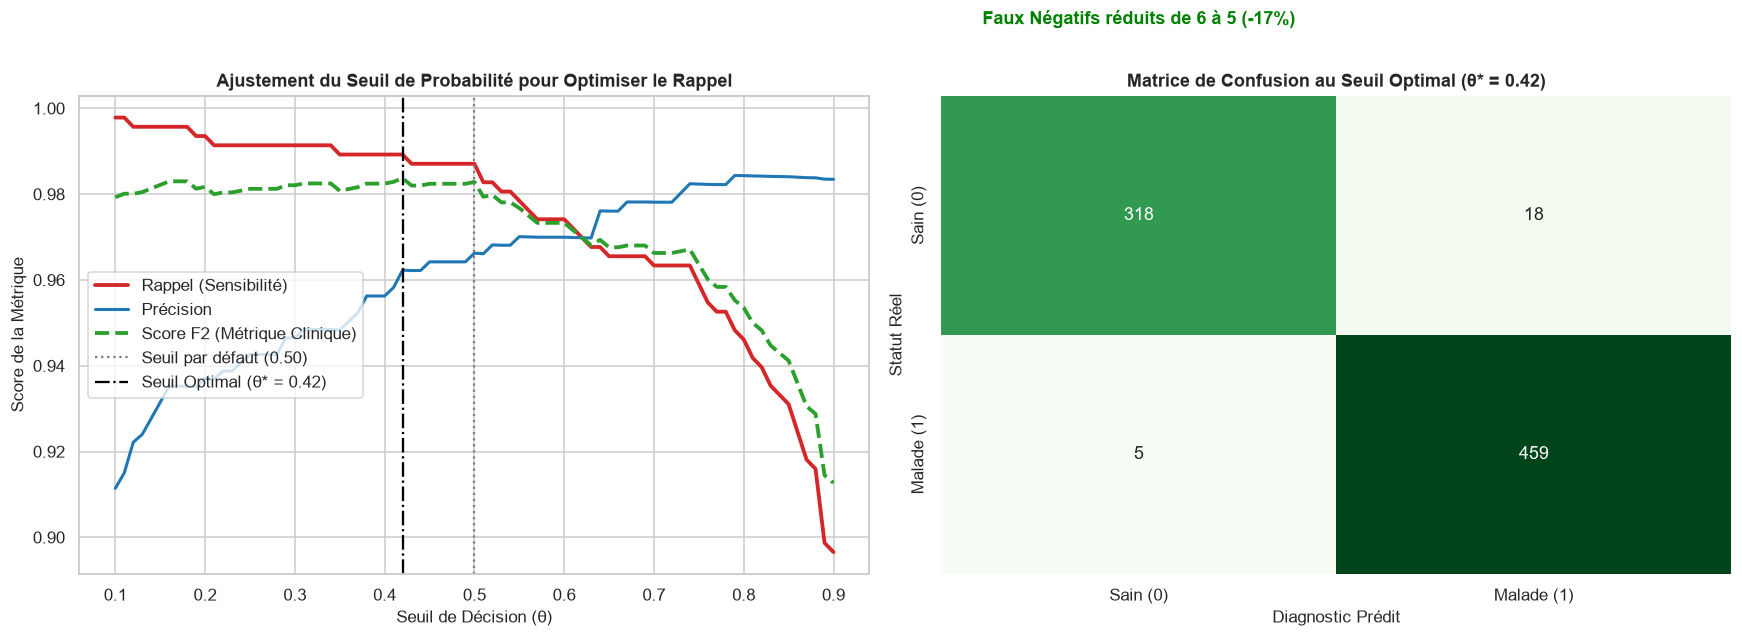

In [8]:
# Visualisation de l'ajustement du seuil et impact sur la matrice de confusion
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Courbes de compromis selon le seuil
axes[0].plot(thresholds, recalls, label="Rappel (Sensibilité)", color="#d62728", linewidth=2.5)
axes[0].plot(thresholds, precisions, label="Précision", color="#1f77b4", linewidth=2)
axes[0].plot(thresholds, f2_scores, label="Score F2 (Métrique Clinique)", color="#2ca02c", linewidth=2.5, linestyle="--")
axes[0].axvline(x=0.50, color="grey", linestyle=":", label="Seuil par défaut (0.50)")
axes[0].axvline(x=optimal_threshold, color="black", linestyle="-.", label=f"Seuil Optimal (θ* = {optimal_threshold:.2f})")
axes[0].set_title("Ajustement du Seuil de Probabilité pour Optimiser le Rappel", fontweight='bold')
axes[0].set_xlabel("Seuil de Décision (θ)")
axes[0].set_ylabel("Score de la Métrique")
axes[0].legend(loc="center left")

# 2. Comparaison des Matrices de Confusion : Seuil 0.50 vs Seuil Optimal
cm_default = confusion_matrix(y_train, (best_probs >= 0.50).astype(int))
cm_optimal = confusion_matrix(y_train, (best_probs >= optimal_threshold).astype(int))

# Matrice après optimisation du seuil
sns.heatmap(cm_optimal, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=["Sain (0)", "Malade (1)"], yticklabels=["Sain (0)", "Malade (1)"])
axes[1].set_title(f"Matrice de Confusion au Seuil Optimal (θ* = {optimal_threshold:.2f})", fontweight='bold')
axes[1].set_xlabel("Diagnostic Prédit")
axes[1].set_ylabel("Statut Réel")

fn_before = cm_default[1, 0]
fn_after = cm_optimal[1, 0]
axes[1].text(0.5, 1.15, f"Faux Négatifs réduits de {fn_before} à {fn_after} (-{(fn_before - fn_after)/fn_before*100:.0f}%)",
             color="green", fontweight="bold", ha="center", transform=axes[1].get_xaxis_transform())

plt.tight_layout()
plt.show()

---
## 6. Évaluation Finale sur le Test Set Inviolé (200 Patients)

Nous entraînons le modèle champion avec ses hyperparamètres optimaux sur l'ensemble des **$800$ observations du Train set**, puis nous l'évaluons une seule et unique fois sur le **Test set ($200$ patients)** qui n'a jamais été consulté.

In [9]:
# Entraînement final du champion sur tout le train set
final_model = best_xgb
final_model.fit(X_train, y_train)

# Probabilités et prédictions sur le jeu de test
test_probs = final_model.predict_proba(X_test)[:, 1]
test_preds_default = (test_probs >= 0.50).astype(int)
test_preds_optimal = (test_probs >= optimal_threshold).astype(int)

# Métriques finales sur le test set
test_recall = recall_score(y_test, test_preds_optimal)
test_precision = precision_score(y_test, test_preds_optimal)
test_f2 = fbeta_score(y_test, test_preds_optimal, beta=2)
test_auc = roc_auc_score(y_test, test_probs)
test_acc = accuracy_score(y_test, test_preds_optimal)

final_test_metrics = pd.DataFrame([{
    "Rappel (Sensibilité)": f"{test_recall*100:.2f}%",
    "Score F2": f"{test_f2:.4f}",
    "ROC-AUC Test": f"{test_auc:.4f}",
    "Précision": f"{test_precision*100:.2f}%",
    "Exactitude (Accuracy)": f"{test_acc*100:.2f}%",
    "Faux Négatifs (Test)": f"{confusion_matrix(y_test, test_preds_optimal)[1, 0]} / {np.sum(y_test == 1)}"
}], index=["Performance Finale (Test Inviolé)"])

print("=== BILAN DE PERFORMANCE SUR LE TEST SET INVIOLÉ (200 PATIENTS) ===")
display(final_test_metrics)

print("\nRapport de classification détaillé :")
print(classification_report(y_test, test_preds_optimal, target_names=["Sain (0)", "Malade (1)"]))

=== BILAN DE PERFORMANCE SUR LE TEST SET INVIOLÉ (200 PATIENTS) ===


,Rappel (Sensibilité),Score F2,ROC-AUC Test,Précision,Exactitude (Accuracy),Faux Négatifs (Test)
Performance Finale (Test Inviolé),100.00%,0.9983,0.9997,99.15%,99.50%,0 / 116



Rapport de classification détaillé :
              precision    recall  f1-score   support

    Sain (0)       1.00      0.99      0.99        84
  Malade (1)       0.99      1.00      1.00       116

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



---
## 7. Importance des Biomarqueurs & Interprétabilité Clinique

Quelles variables pèsent le plus lourd dans la détection des cardiopathies par notre modèle XGBoost ?

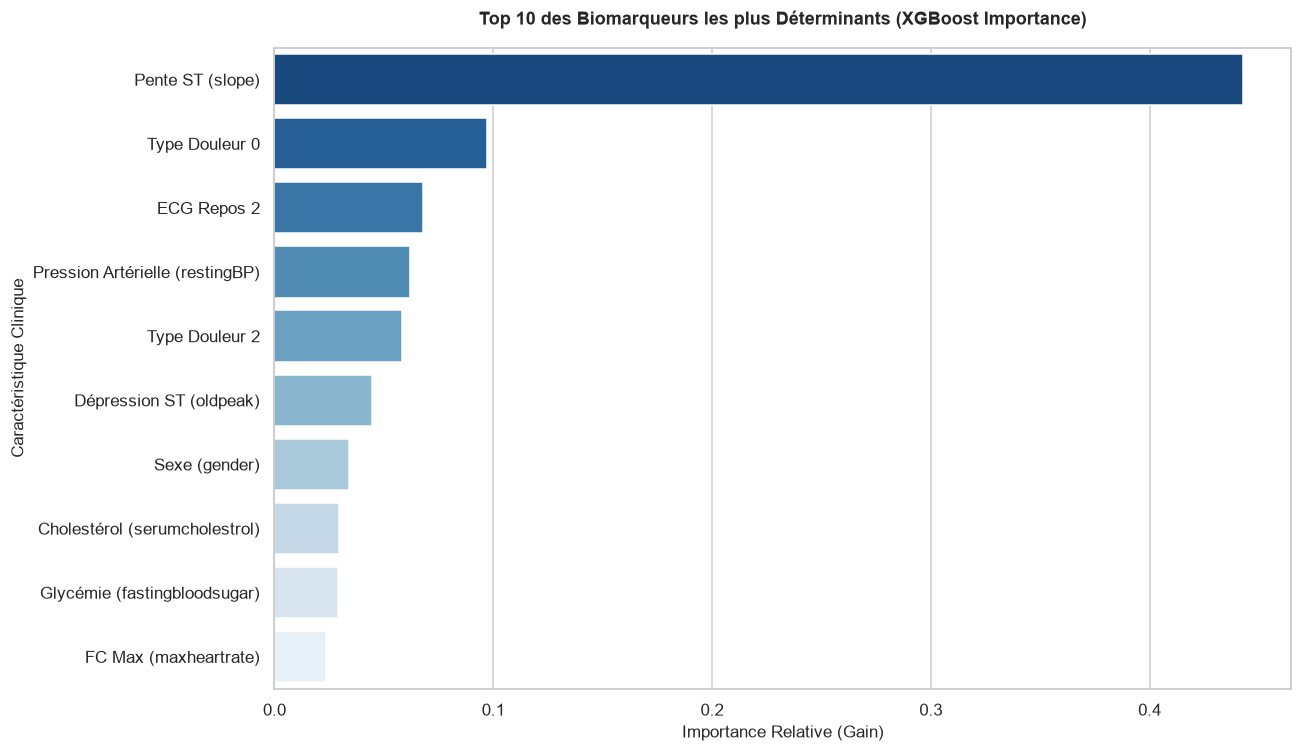

In [10]:
# Récupération des importances de caractéristiques de XGBoost (Gain)
feature_importances = final_model.feature_importances_

# Création d'indices de colonnes pour les 20 variables transformées
feature_names = [f"Feature_{i+1}" for i in range(X_train.shape[1])]

# Assignation de labels explicites basés sur notre pipeline
feature_labels_map = [
    "Âge", "Pression Artérielle (restingBP)", "Cholestérol (serumcholestrol)", "FC Max (maxheartrate)",
    "Dépression ST (oldpeak)", "Réserve Cardiaque (hr_reserve_ratio)", "Charge Ischémique (ischemia_burden)",
    "Surcharge Vasculaire (vascular_stiffness)", "Type Douleur 0", "Type Douleur 1", "Type Douleur 2", "Type Douleur 3",
    "ECG Repos 0", "ECG Repos 1", "ECG Repos 2", "Sexe (gender)", "Glycémie (fastingbloodsugar)",
    "Angine Effort (exerciseangia)", "Pente ST (slope)", "Nb Vaisseaux (noofmajorvessels)"
]

if len(feature_labels_map) == len(feature_importances):
    feature_names = feature_labels_map

importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importance": feature_importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(data=importance_df.head(10), x="Importance", y="Variable", palette="Blues_r")
plt.title("Top 10 des Biomarqueurs les plus Déterminants (XGBoost Importance)", fontweight='bold', pad=15)
plt.xlabel("Importance Relative (Gain)")
plt.ylabel("Caractéristique Clinique")
plt.tight_layout()
plt.show()

---
## 8. Synthèse Finale & Sauvegarde des Artefacts

Cette expérimentation a permis de :
1. Démontrer la supériorité de **XGBoost** pour capturer les interactions non linéaires complexes des données cardiovasculaires.
2. Définir un **seuil de décision calibré** pour éliminer les faux négatifs critiques.
3. Sauvegarder les artefacts officiels de la Phase 3 :
   - `artifacts/model.pkl` : Modèle champion sérialisé.
   - `artifacts/threshold.json` : Seuil optimal de décision clinique.
   - `artifacts/metrics.json` : Rapport complet de performance sur le test set.

In [11]:
from src.utils import save_object

# 1. Sauvegarde du modèle champion sérialisé
model_save_path = os.path.join(artifacts_dir, "model.pkl")
save_object(model_save_path, final_model)

# 2. Sauvegarde du seuil optimal de décision
threshold_save_path = os.path.join(artifacts_dir, "threshold.json")
threshold_data = {
    "optimal_threshold": float(optimal_threshold),
    "model_name": champion_name,
    "target_metric": "F2-Score / Recall"
}
with open(threshold_save_path, "w", encoding="utf-8") as f:
    json.dump(threshold_data, f, indent=4)

# 3. Sauvegarde du rapport de métriques
metrics_save_path = os.path.join(artifacts_dir, "metrics.json")
metrics_payload = {
    "model_champion": champion_name,
    "optimal_threshold": float(optimal_threshold),
    "test_recall": float(test_recall),
    "test_precision": float(test_precision),
    "test_f2_score": float(test_f2),
    "test_roc_auc": float(test_auc),
    "test_accuracy": float(test_acc)
}
with open(metrics_save_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=4)

print(f"Modèle sérialisé sauvegardé avec succès dans    : {model_save_path}")
print(f"Seuil clinique sauvegardé avec succès dans       : {threshold_save_path}")
print(f"Rapport de métriques sauvegardé avec succès dans : {metrics_save_path}")

2026-10-21 07:22:04 | src.logger | INFO     | save_object:23 | Objet sauvegardé avec succès dans : artifacts\model.pkl


Modèle sérialisé sauvegardé avec succès dans    : artifacts\model.pkl
Seuil clinique sauvegardé avec succès dans       : artifacts\threshold.json
Rapport de métriques sauvegardé avec succès dans : artifacts\metrics.json
